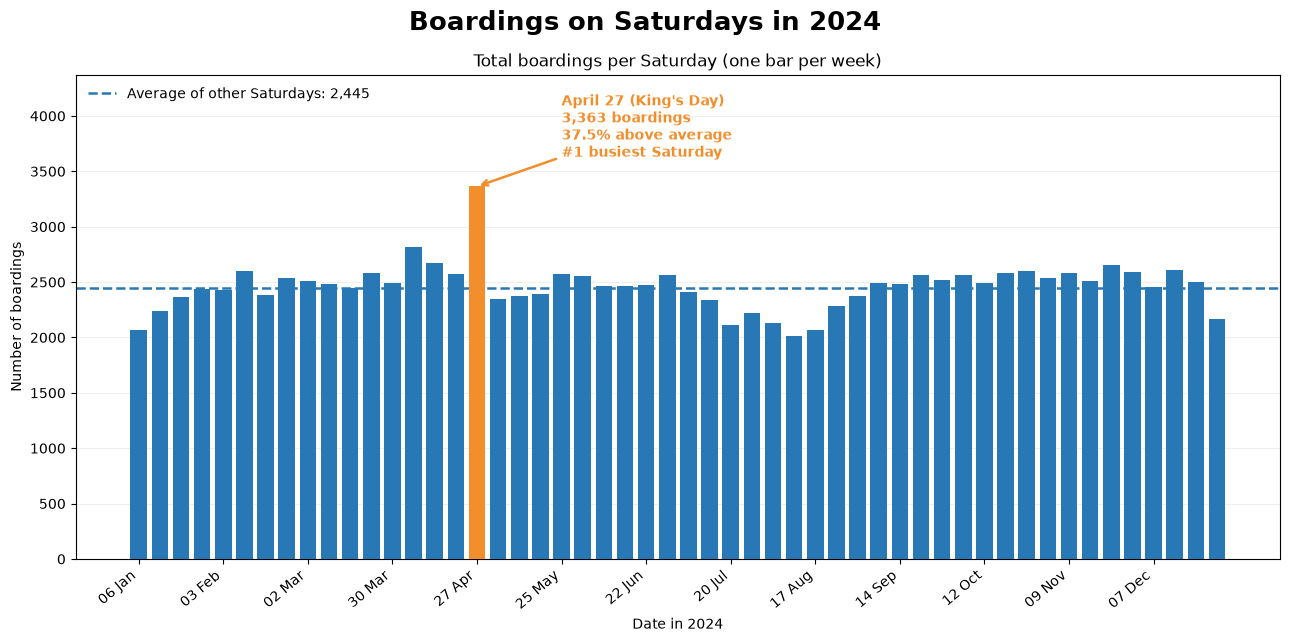

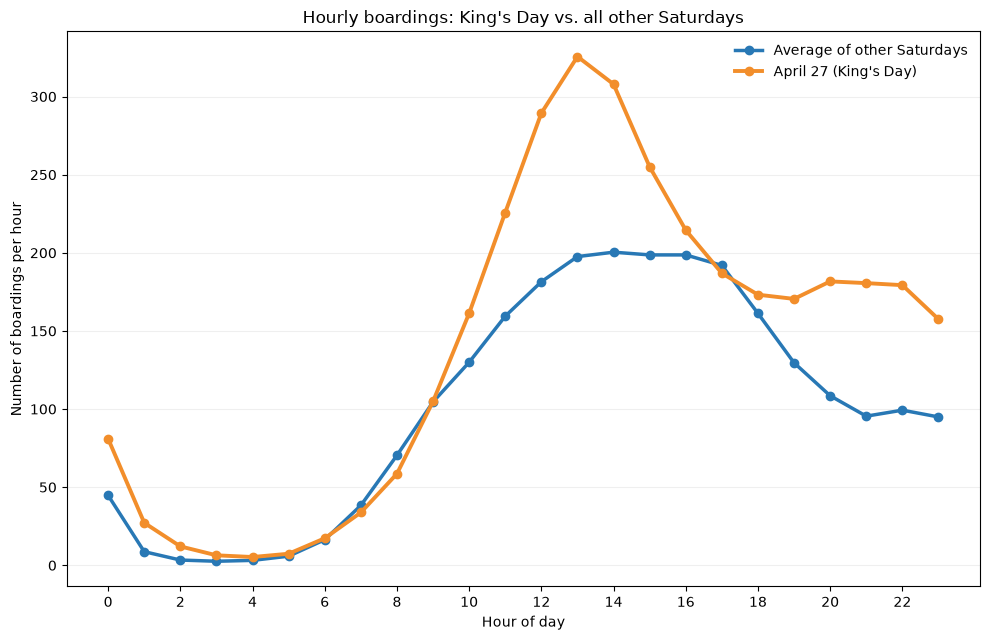

Saturdays: 52 | April 27: 3,363.2 boardings | average of other Saturdays: 2,445.3 | difference: +37.5% | rank: 1 of 52


In [7]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import os

#Loading CSV from data map into dataframe

csv_path = os.path.join("..", "Data", "Instappers_per_uur_export_V3_2024.csv")

df = pd.read_csv(
    csv_path,
    skiprows=1,
    names=["Date", "Hour", "Number_of_check_ins"],
    quoting=csv.QUOTE_NONE,
)
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df["Hour"] = pd.to_numeric(df["Hour"])
df["Number_of_check_ins"] = pd.to_numeric(
    df["Number_of_check_ins"].astype(str).str.strip('"')
)

#Selecting all saturdays and calculating total boardings per Saturday
Saturdays = df.loc[df["Date"].dt.dayofweek == 5].copy()
Weektotals = (
    Saturdays.groupby("Date")["Number_of_check_ins"]
    .sum()
    .sort_index()
)
Kingsday = pd.Timestamp("2024-04-27")
if Kingsday not in Weektotals.index:
    raise ValueError

blue = "#2878B5"
orange = "#F28E2B"
average = Weektotals.drop(Kingsday).mean()
kingsday_total = Weektotals.loc[Kingsday]
percent_above_average = (kingsday_total / average - 1) * 100
rank = int(Weektotals.rank(ascending=False, method="min").loc[Kingsday])

#comparative analysis of hourly boardings on King's Day vs. all other Saturdays
other_saturdays = Saturdays.loc[Saturdays["Date"].ne(Kingsday)]
average_per_hour = (
    other_saturdays.groupby(["Date", "Hour"])["Number_of_check_ins"]
    .sum()
    .groupby("Hour")
    .mean()
)
Kingsday_per_hour = (
    Saturdays.loc[Saturdays["Date"].eq(Kingsday)]
    .set_index("Hour")["Number_of_check_ins"]
    .sort_index()
)

fig_week, ax_week = plt.subplots(figsize=(13, 6.5))
fig_week.suptitle("Boardings on Saturdays in 2024", fontsize=19, fontweight="bold")

# Daily total per Saturday; King's Day is highlighted in orange.
colors = [orange if date == Kingsday else blue for date in Weektotals.index]
ax_week.bar(Weektotals.index, Weektotals.values, color=colors, width=5.5, zorder=3)
ax_week.axhline(
    average,
    color=blue,
    linestyle="--",
    linewidth=1.8,
    label=f"Average of other Saturdays: {average:,.0f}",
)
ax_week.annotate(
    f"April 27 (King's Day)\n{kingsday_total:,.0f} boardings\n"
    f"{percent_above_average:.1f}% above average\n#{rank} busiest Saturday",
    xy=(Kingsday, kingsday_total),
    xytext=(Kingsday + pd.Timedelta(days=28), kingsday_total * 1.08),
    color=orange,
    fontweight="bold",
    arrowprops={"arrowstyle": "->", "color": orange, "lw": 1.8},
    ha="left",
)
ax_week.set_title("Total boardings per Saturday (one bar per week)")
ax_week.set_ylabel("Number of boardings")
ax_week.set_xlabel("Date in 2024")
month_abbreviations = ("Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec")
ax_week.set_xticks(Weektotals.index[::4])
ax_week.set_xticklabels(
    [f"{datum.day:02d} {month_abbreviations[datum.month - 1]}" for datum in Weektotals.index[::4]],
    rotation=40,
    ha="right",
)
ax_week.set_ylim(0, Weektotals.max() * 1.3)
ax_week.grid(axis="y", alpha=0.2, zorder=0)
ax_week.legend(frameon=False, loc="upper left")

fig_week.tight_layout()
os.makedirs(os.path.join("..", "Figures"), exist_ok=True)
plt.savefig(os.path.join("..", "Figures", "figure8.png"), dpi=150, bbox_inches="tight")
plt.show()

# Right: compare hourly boardings on King's Day with all other Saturdays.
fig_hour, ax_hour = plt.subplots(figsize=(10, 6.5))
ax_hour.plot(
    average_per_hour.index,
    average_per_hour.values,
    color=blue,
    marker="o",
    linewidth=2.5,
    label="Average of other Saturdays",
)
ax_hour.plot(
    Kingsday_per_hour.index,
    Kingsday_per_hour.values,
    color=orange,
    marker="o",
    linewidth=2.8,
    label="April 27 (King's Day)",
)
ax_hour.set_title("Hourly boardings: King's Day vs. all other Saturdays")
ax_hour.set_xlabel("Hour of day")
ax_hour.set_ylabel("Number of boardings per hour")
ax_hour.set_xticks(range(0, 24, 2))
ax_hour.grid(axis="y", alpha=0.2)
ax_hour.legend(frameon=False)

fig_hour.tight_layout()
os.makedirs(os.path.join("..", "Figures"), exist_ok=True)
plt.savefig(os.path.join("..", "Figures", "figure9.png"), dpi=150, bbox_inches="tight")
plt.show()

print(
    f"Saturdays: {len(Weektotals)} | "
    f"April 27: {kingsday_total:,.1f} boardings | "
    f"average of other Saturdays: {average:,.1f} | "
    f"difference: +{percent_above_average:.1f}% | "
    f"rank: {rank} of {len(Weektotals)}"
)
